# **Classification**

**Introduction**

This part of the coursework investigates a classification problem addressing the severity of road traffic accidents using the FARS dataset. This dataset has a large-scale collection of US road traffic accidents containing over 100,00 records and 20 features. The target variable here represents accident severity and exhibits significant class imbalance. This makes the task complex and challenging.

The objective of this part of the coursework is to develop and evaluate four machine learning pipelines. The main tasks include data preprocessing, handling class imbalance, cross-validated hyperparameter tuning and robust evaluation metrics suitable to perform the task for imbalanced multi-class classification. The models are evaluate using macro-averaged metrics and the results are discussed.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MaxAbsScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

**Data Loading and Initial Setup**

The fars.csv dataset is mounted from google drive and loaded into colab environment. A fixed random seed is set to guarantee consistent experimental results across runs.
The presence of extremely rare severity classes with insufficient samples can cause exceptions hence have to be removed prior to modelling. This step ensures stratified cross-validation and prevents failures during SMOTE oversampling which requires a minimum number of samples per class. As this filtering affects a very small portion of the data, it does not affect or alter the overall class distribution.

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)
df = pd.read_csv("/content/drive/MyDrive/MLCData/fars.csv")

Mounted at /content/drive


In [ ]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

target_col_name = df.columns[-1] #Assuming target is always the last column
class_counts_sampled = df[target_col_name].value_counts()

min_samples_required = max(5, 3 + 1) #max(n_splits, SMOTE k_neighbors + 1)
rare_classes_to_exclude = class_counts_sampled[class_counts_sampled < min_samples_required].index.tolist()

if rare_classes_to_exclude:
    print(f"Removing rows belonging to classes too rare for SMOTE and StratifiedKFold: {rare_classes_to_exclude}")
    df = df[~df[target_col_name].isin(rare_classes_to_exclude)]
else:
    print("No extremely rare classes found in sampled data to exclude.")

No extremely rare classes found in sampled data to exclude.


**Exploratory Data Analysis (EDA)**


*  Dataset Overview: A dataset overview table summarises the total number of instances, the number of features, and the breakdown between numerical and categorical variables. The FARS dataset contains a mixture of continuous and categorical attributes, requiring different preprocessing strategies.

*   Target Class Distribution: The target variable distribution is examined numerically and visually. A severe class imbalance is clearly demonstrated in the class distribution table and corresponding bar chart.
This imbalance requires the usage of macro-averaged evaluation metrics and explicit class imbalance handling strategies such as SMOTE and class weighting.[1]

*   Missing Values: The proportion of missing values per feature is analysed and visualised in Figure 2. Several features evidently exhibit substantial missingness, justifying the use of imputation as part of the preprocessing pipeline. Overall, the EDA provides a clear understanding of the dataset structure and directly influences subsequent modelling decisions.

In [ ]:
#1) EDA
target_col = df.columns[-1]
print("Shape:", df.shape)

print("\nTarget distribution:")
print(df[target_col].value_counts(dropna=False))

print("\n% missing (top 10):")
missing_pct = (df.isna().mean().sort_values(ascending=False) * 100).round(2)
display(missing_pct.head(10).rename("% missing"))

plt.style.use("ggplot")

Shape: (100968, 30)

Target distribution:
INJURY_SEVERITY
Fatal_Injury                      42116
No_Injury                         20007
Incapaciting_Injury               15072
Nonincapaciting_Evident_Injury    13890
Possible_Injury                    8674
Unknown                             901
Injured_Severity_Unknown            299
Died_Prior_to_Accident                9
Name: count, dtype: int64

% missing (top 10):


,% missing
CASE_STATE,0.0
AGE,0.0
SEX,0.0
PERSON_TYPE,0.0
SEATING_POSITION,0.0
RESTRAINT_SYSTEM-USE,0.0
AIR_BAG_AVAILABILITY/DEPLOYMENT,0.0
EJECTION,0.0
EJECTION_PATH,0.0
EXTRICATION,0.0


Table: Dataset Overview


,Rows,Features (excluding target),Numeric features,Categorical features,Target column,Num classes
0,100968,29,5,24,INJURY_SEVERITY,8


Table: Target Class Distribution


,Class,Count,Percent
0,Fatal_Injury,42116,41.71
1,No_Injury,20007,19.82
2,Incapaciting_Injury,15072,14.93
3,Nonincapaciting_Evident_Injury,13890,13.76
4,Possible_Injury,8674,8.59
5,Unknown,901,0.89
6,Injured_Severity_Unknown,299,0.30
7,Died_Prior_to_Accident,9,0.01


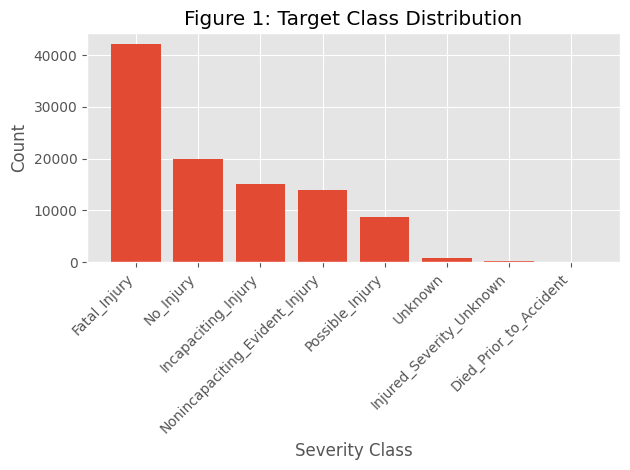

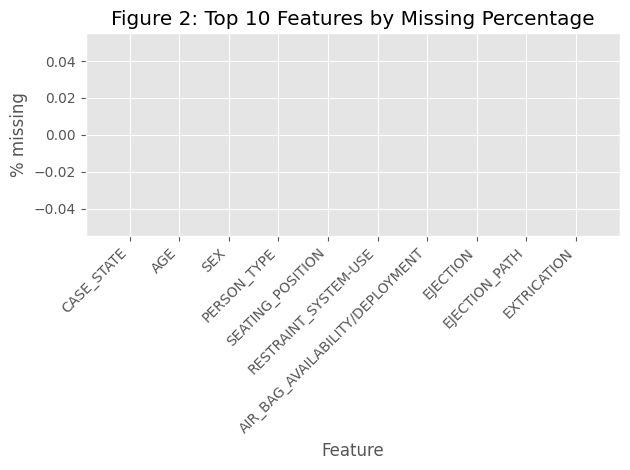

In [ ]:
#1.1) EDA TABLES + PLOTS (reporting only)
#Table A: Dataset overview
numeric_cols_all = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols_all = [c for c in df.columns[:-1] if c not in numeric_cols_all]  #exclude target
overview_table = pd.DataFrame([{
    "Rows": df.shape[0],
    "Features (excluding target)": df.shape[1] - 1,
    "Numeric features": len([c for c in df.columns[:-1] if c in numeric_cols_all]),
    "Categorical features": len(categorical_cols_all),
    "Target column": target_col,
    "Num classes": df[target_col].nunique()
}])
print("Table: Dataset Overview")
display(overview_table)

#Table B: Target distribution (count + %)
target_dist_table = (
    df[target_col]
    .value_counts(dropna=False)
    .rename_axis("Class")
    .reset_index(name="Count")
)
target_dist_table["Percent"] = (target_dist_table["Count"] / target_dist_table["Count"].sum() * 100).round(2)
print("Table: Target Class Distribution")
display(target_dist_table)

#Figure 1: Target distribution bar chart
plt.figure()
plt.bar(target_dist_table["Class"].astype(str), target_dist_table["Count"])
plt.title("Figure 1: Target Class Distribution")
plt.xlabel("Severity Class")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#Figure 2: Top missingness bar chart
top_missing = missing_pct.head(10)
plt.figure()
plt.bar(top_missing.index.astype(str), top_missing.values)
plt.title("Figure 2: Top 10 Features by Missing Percentage")
plt.xlabel("Feature")
plt.ylabel("% missing")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Train–Test Split and Cross-Validation Strategy**

The dataset is first split into two parts, namely training (80%) and test (20%) sets using stratified sampling to preserve the original class distribution. All model selection and hyperparameter tuning is performed on the training set.
Stratified k-fold cross-validation (k=3) is used during hyperparameter tuning to ensure robust performance estimation across imbalanced classes and simultaneously maintain computational efficiency given the massive size of the data.

In [ ]:
#2) Split features/target
X = df.iloc[:, :-1].copy()
y = df.iloc[:, -1].copy().astype("category")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTrain:", X_train.shape, "Test:", X_test.shape)


Train: (80774, 29) Test: (20194, 29)


**Data Preprocessing**

Preprocessing is implemented using scikit-learn pipelines. This avoids data leakage and ensures reproducibility.

* **Numeric Features:**
* Missing values are imputed using the median.
* Scaling is applied for logistic regression using MaxAbsScaler, which is compatible with sparse one-hot encoded features.
* **Categorical Features:**
* Missing values are then imputed using the most frequent category.
* One-hot encoding is used and applied with min_frequency=10 to merge rare categories and control dimensionality.
* This design ensures the reduction of feature explosion while not compromising on the informative categories.
* **Feature Selection Considerations:**
* Explicit feature selection was considered but not applied. Tree-based models perform feature selection through split criteria and logistic regression which is regularised and trained on a reduced feature space due to frequency based one-hot encoding. Hence, an additional feature selection stage was not considered necessary.

In [ ]:
#3) Build preprocessing
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

print("\nNumeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

numeric_imputer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_imputer_ohe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))
])

#Trees
preprocess_tree = ColumnTransformer(
    transformers=[
        ("num", numeric_imputer, numeric_features),
        ("cat", categorical_imputer_ohe, categorical_features)
    ],
    remainder="drop"
)

#Logistic Regression
preprocess_scaled = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", MaxAbsScaler())
        ]), numeric_features),
        ("cat", categorical_imputer_ohe, categorical_features)
    ],
    remainder="drop"
)



Numeric features: 5
Categorical features: 24


**Machine Learning Pipelines**

Four distinct machine learning pipelines are constructed and implemented:

*   **Decision Tree:** The decision tree is a baseline interpretable model which is tuned for depth and node size with optional class weighting to mitigate imbalance.[2]
*   **Decision Tree + SMOTE:** The decision tree + SMOTE pipeline applies SMOTE oversampling within the training folds to address class imbalance before training a decision tree.
*   **Random Forest:** An ensemble of decision trees designed to reduce overfitting and capture non-linear feature interactions. Class weighting is optionally applied.[3]
*   **Logistic Regression:** Logistic regression is used as a linear baseline model trained with regularisation and class weighting. Stable optimisation is ensured by applying scaling to the numeric features.[4]

  Together, these pipelines represent a broad range of modelling strategies and complexities.

In [ ]:
#4) FOUR pipelines

pipe_dt = Pipeline(steps=[
    ("preprocess", preprocess_tree),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

pipe_dt_smote = ImbPipeline(steps=[
    ("preprocess", preprocess_tree),
    ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

pipe_rf = Pipeline(steps=[
    ("preprocess", preprocess_tree),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
])

pipe_lr = Pipeline(steps=[
    ("preprocess", preprocess_scaled),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

pipelines = {
    "DecisionTree": pipe_dt,
    "DecisionTree+SMOTE": pipe_dt_smote,
    "RandomForest": pipe_rf,
    "LogisticRegression": pipe_lr
}

**Hyperparameter Tuning**

Hyperparameters are tuned using RandomizedSearchCV. This provides an efficient alternative to exhaustive grid search. Model-specific parameter spaces are defined for all the pipelines including tree depth, number of estimators, regularisation strength and class weighing options. To reduce computational cost and not compromise on the performance due to excessively large grids he Random Forest search space was intentionally restricted to reduce the computational cost and the diminishing performance gains from excessively large grids.
The optimisation objective is macro-averaged F1 score, which is efficient as treates all classes equally and is appropriate for imbalanced multi-class classification.

In [ ]:
#5) Hyperparameter search spaces
param_distributions = {
    "DecisionTree": {
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [None, 5, 10, 20, 40],
        "model__min_samples_split": [2, 5, 10, 20],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__class_weight": [None, "balanced"]
    },
    "DecisionTree+SMOTE": {
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [None, 5, 10, 20, 40],
        "model__min_samples_split": [2, 5, 10, 20],
        "model__min_samples_leaf": [1, 2, 5, 10]
    },
    "RandomForest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [10, 20, 40],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2", None],
        "model__class_weight": [None, "balanced"]
    },
    "LogisticRegression": {
        "model__C": np.logspace(-3, 2, 15),
        "model__class_weight": [None, "balanced"]
    }
}

In [ ]:
#6) CV and scoring
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scoring = "f1_macro"

**Evaluation Metrics**

Model performance is evaluated using:
* Accuracy
* Balanced accuracy
* Macro-averaged F1 score (primary metric)

Macro-F1 is prioritised because it penalises poor performance on minority classes, which are critical in accident severity prediction.
In this accident severity prediction, it is essential to give precedence to Macro-F1 as it penalises poor performance on minority classes.
Confusion matrices (both raw and normalised) and per-class precision, recall, and F1 scores are also reported for the best model to provide deeper insight into class-level behaviour. Limited number of iterations are used on RandomizedSearchCV to efficiently explore the hyperparameter space and lower the computational cost.
Confusion matrices and per-class precision, recall and F1 scores are reported for the best model to provide an insight into class-level behaviour.

In [ ]:
#7) Train/tune each pipeline
results = []
best_models = {}

N_ITER = 10

for name, pipe in pipelines.items():
    print(f"{name}")

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_distributions[name],
        n_iter=N_ITER,
        scoring=scoring,
        cv=cv,
        verbose=1,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        error_score="raise"
    )

    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_

    print("Best CV f1_macro:", search.best_score_)
    print("Best parameters:", search.best_params_)

    y_pred = search.best_estimator_.predict(X_test)

    results.append({
        "Pipeline": name,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Balanced Acc": balanced_accuracy_score(y_test, y_pred),
        "Test F1 Macro": f1_score(y_test, y_pred, average="macro"),
        "Best CV F1 Macro": search.best_score_
    })

DecisionTree
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV f1_macro: 0.544740414089646
Best parameters: {'model__min_samples_split': 20, 'model__min_samples_leaf': 10, 'model__max_depth': 20, 'model__criterion': 'gini', 'model__class_weight': None}
DecisionTree+SMOTE
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV f1_macro: 0.5468959948975652
Best parameters: {'model__min_samples_split': 5, 'model__min_samples_leaf': 10, 'model__max_depth': 20, 'model__criterion': 'entropy'}
RandomForest
Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best CV f1_macro: 0.5576969016969776
Best parameters: {'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': None, 'model__max_depth': 40, 'model__class_weight': None}
LogisticRegression
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV f1_macro: 0.548520570100793
Best parameters: {'model__class_weight': None, 'model__C': np.float64(19.306977288832496)}


**Results and Model Comparison**

The test set performance summary compares all four pipelines. Random forest achieves the highest macro-F1 score (≈0.56) and balanced accuracy, indicating the best overall performance across all severity classes.
Logistic regression achieved\s slightly higher overall accuracy, but it is necessary to note that its lower macro-F1 score highlights its bias towards majority classes. Decision tree-based models do not perform well overall and the addition of SMOTE does not make much improvement, likely due to noise introduced by synthetic samples in a high-dimensional feature space.
Figure 3 visually compares macro-F1 scores across pipelines, clearly identifying Random Forest as the best-performing model.

The confusion matrices are inserted here for the best performing random forest model (Figures 4 and 5). These reveal that most misclassifications occur between neighbouring security levels, which is expected given that accident severity is of ordinal nature. Minority classes remain a challenge to predict reinforcing the importance of imbalance-aware metrics.

Table: Test Set Performance Summary (sorted by Test F1 Macro)


,Pipeline,Test Accuracy,Test Balanced Acc,Test F1 Macro,Best CV F1 Macro
2,RandomForest,0.790185,0.555241,0.563396,0.557697
3,LogisticRegression,0.803655,0.560090,0.559283,0.548521
0,DecisionTree,0.791522,0.538854,0.546059,0.544740
1,DecisionTree+SMOTE,0.786174,0.549934,0.542896,0.546896


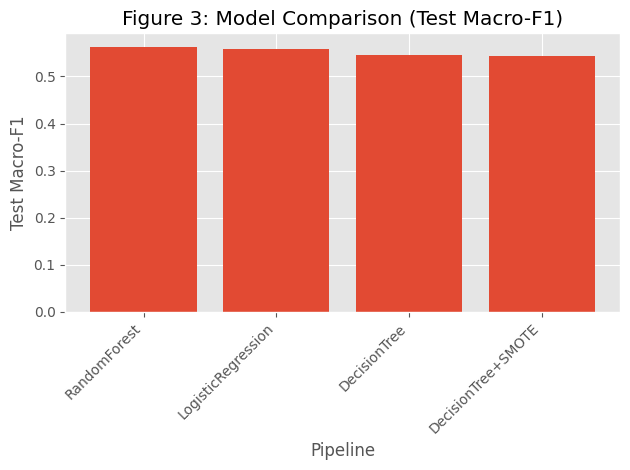

Best pipeline: RandomForest

Confusion Matrix:
[[   0    0    0    0    2    0    0    0]
 [   0 8413    0    0    0    0    0   10]
 [   0    0 1821    2    4 1004  183    0]
 [   0    0   11   25    1   16    7    0]
 [   0    0    6    1 3780   40  149   26]
 [   0    0 1016    7  122 1386  242    5]
 [   0    0  345    6  420  564  397    3]
 [   0    1    1    0   32    8    3  135]]

Classification Report:


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                                precision    recall  f1-score   support

        Died_Prior_to_Accident       0.00      0.00      0.00         2
                  Fatal_Injury       1.00      1.00      1.00      8423
           Incapaciting_Injury       0.57      0.60      0.59      3014
      Injured_Severity_Unknown       0.61      0.42      0.50        60
                     No_Injury       0.87      0.94      0.90      4002
Nonincapaciting_Evident_Injury       0.46      0.50      0.48      2778
               Possible_Injury       0.40      0.23      0.29      1735
                       Unknown       0.75      0.75      0.75       180

                      accuracy                           0.79     20194
                     macro avg       0.58      0.56      0.56     20194
                  weighted avg       0.78      0.79      0.78     20194



<Figure size 640x480 with 0 Axes>

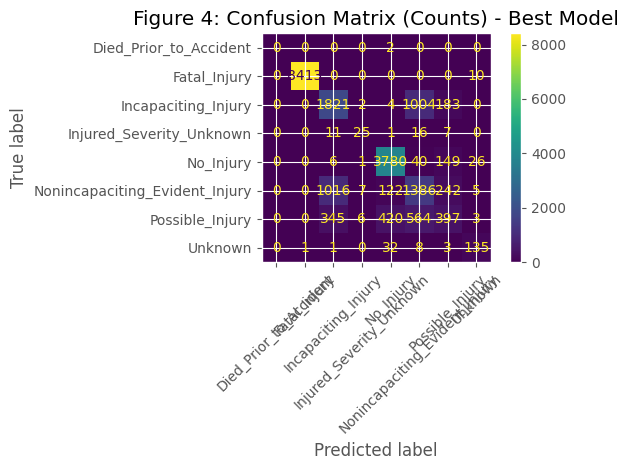

<Figure size 640x480 with 0 Axes>

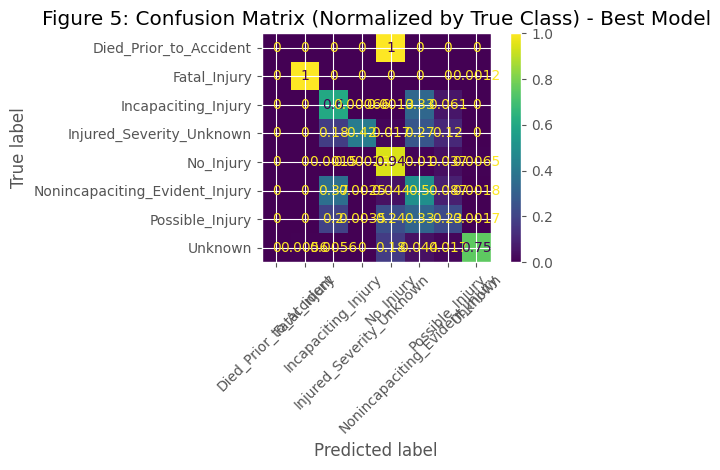

Table: Per-class Metrics (Best Model)


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,precision,recall,f1-score,support
Died_Prior_to_Accident,0.000000,0.000000,0.000000,2.000000
Fatal_Injury,0.999881,0.998813,0.999347,8423.000000
Incapaciting_Injury,0.569063,0.604180,0.586096,3014.000000
Injured_Severity_Unknown,0.609756,0.416667,0.495050,60.000000
No_Injury,0.866774,0.944528,0.903982,4002.000000
Nonincapaciting_Evident_Injury,0.459245,0.498920,0.478261,2778.000000
Possible_Injury,0.404689,0.228818,0.292342,1735.000000
Unknown,0.754190,0.750000,0.752089,180.000000
accuracy,0.790185,0.790185,0.790185,0.790185
macro avg,0.582950,0.555241,0.563396,20194.000000



We evaluated four classification pipelines for FARS severity prediction. Hyperparameters were tuned using Stratified cross-validation optimizing macro-F1, which is appropriate for imbalanced multi-class classification.
Best pipeline on the independent test set: RandomForest.



In [ ]:
#8) Summary

results_df = pd.DataFrame(results).sort_values(by="Test F1 Macro", ascending=False)
print("Table: Test Set Performance Summary (sorted by Test F1 Macro)")
display(results_df)

#Performance comparison plot
plt.figure()
plt.bar(results_df["Pipeline"], results_df["Test F1 Macro"])
plt.title("Figure 3: Model Comparison (Test Macro-F1)")
plt.xlabel("Pipeline")
plt.ylabel("Test Macro-F1")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

best_name = results_df.iloc[0]["Pipeline"]
best_model = best_models[best_name]

print(f"Best pipeline: {best_name}")
y_pred_best = best_model.predict(X_test)

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_best)
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

#Confusion matrix plots

# Figure 4: Confusion matrix (raw counts)
plt.figure()
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, xticks_rotation=45)
plt.title("Figure 4: Confusion Matrix (Counts) - Best Model")
plt.tight_layout()
plt.show()

# Figure 5: Confusion matrix (normalized)
plt.figure()
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, normalize="true", xticks_rotation=45)
plt.title("Figure 5: Confusion Matrix (Normalized by True Class) - Best Model")
plt.tight_layout()
plt.show()

# Table: Per-class metrics from classification report (best model)
report_dict = classification_report(y_test, y_pred_best, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
print("Table: Per-class Metrics (Best Model)")
display(report_df)

print(f"""
We evaluated four classification pipelines for FARS severity prediction. Hyperparameters were tuned using Stratified cross-validation optimizing macro-F1, which is appropriate for imbalanced multi-class classification.
Best pipeline on the independent test set: {best_name}.
""")

**Conclusion**

The results are obtained by evaluating four machine learning pipelines for US road traffic accident severity classification using the FARS dataset. This study clearly demonstrates ensemble methods, particularly random forests, given that it provides the best balance between performance and robustness in the presence of class imbalance.

Using simpler models like logistic regression would have performed competitively, there is some struggle to capture non-linear relationships present in the data. Direct oversampling using SMOTE did not improve results in this setting, highlighting the need to carefully handle imbalance.
Further work could explore other imbalance techniques, additional feature engineering, or ordinal classification approaches to improve performance.

# **Regression**

**Introduction**

This part of the coursework requires a complete machine-learning workflow for a regression problem which predicts four continuous growth parameters of bacteria from experimental conditions. Four different regression pipelines are trained and evaluated independently for each target.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

**Data Loading and Initial Setup**

The fars.csv dataset is mounted from google drive and loaded into colab environment. A fixed random seed is set to guarantee consistent experimental results across runs. T

In [ ]:
#Load data
DATA_PATH = "/content/drive/MyDrive/MLRData/fitting-results.csv"
df = pd.read_csv(DATA_PATH)

**Exploratory Data Analysis (EDA)**

Distribution Plots: Histograms are created for all input features and target variables. This helps to check the range and distribution of variables, identify skewness and inspect whether scaling may be necessary.

Correlation Heatmap: A heat map has been used to visualise correlation matrix. This helps in checking for relationships between experimental inputs and growth parameters, multicollinearity and for informative features that could be used for prediction.

In [ ]:
#1) EDA
print("Shape:", df.shape)
display(df.head())
display(df.describe(include="all"))

#Checking for missing values
print("\nMissing values per column:")
display(df.isna().sum())

#Correlation with targets
targets = ["a", "mu", "tau", "a0"]
display(df.corr(numeric_only=True)[targets].sort_values(by="a", ascending=False))

Shape: (19992, 9)


,n_cyanos,co2,light,SucRatio,Nsample,a,mu,tau,a0
0,262,73.578860,0.367894,0.451505,13123,5.033993,5.483011,0.552466,1.0
1,610,74.582194,0.481606,0.969900,12474,1.018406,1.830727,0.156458,1.0
2,118,33.111037,0.625418,0.909699,8867,2.569159,3.330662,0.412541,1.0
3,159,8.027676,0.575251,0.137124,16494,1.837341,3.371570,0.260798,1.0
4,957,38.796599,0.939799,0.234114,10267,0.999268,2.059303,0.098619,1.0


,n_cyanos,co2,light,SucRatio,Nsample,a,mu,tau,a0
count,19992.000000,19992.000000,19992.000000,19992.000000,19992.000000,19992.000000,19992.000000,1.999200e+04,19992.000000
mean,494.367547,49.890457,0.495162,0.496075,9997.371349,5.490172,5.634110,3.731908e-01,0.991562
std,288.957886,29.138328,0.289767,0.289731,5772.058433,13.441047,9.862259,4.211606e-01,0.017142
min,2.000000,0.001000,0.000001,0.000000,1.000000,0.000004,0.000539,4.940656e-324,0.886770
25%,242.000000,24.415472,0.234114,0.240803,4998.750000,0.703064,1.852808,6.283220e-02,0.993737
50%,499.000000,49.833278,0.494984,0.494983,9997.500000,1.775632,3.037436,2.692814e-01,1.000000
75%,740.000000,75.251084,0.742475,0.742475,14995.250000,4.210368,5.038206,4.785551e-01,1.000000
max,1000.000000,100.000000,1.000000,1.000000,19995.000000,162.186465,123.376876,2.259995e+00,1.000000



Missing values per column:


,0
n_cyanos,0
co2,0
light,0
SucRatio,0
Nsample,0
a,0
mu,0
tau,0
a0,0


,a,mu,tau,a0
a,1.000000,0.996551,0.865091,0.179102
mu,0.996551,1.000000,0.863102,0.196466
tau,0.865091,0.863102,1.000000,0.385261
co2,0.209350,0.209381,0.398286,0.297470
a0,0.179102,0.196466,0.385261,1.000000
light,0.008905,0.011367,0.016869,0.006131
Nsample,-0.004175,-0.003562,-0.010817,-0.000274
SucRatio,-0.195975,-0.231578,-0.256130,-0.219768
n_cyanos,-0.444273,-0.442704,-0.630056,-0.277167


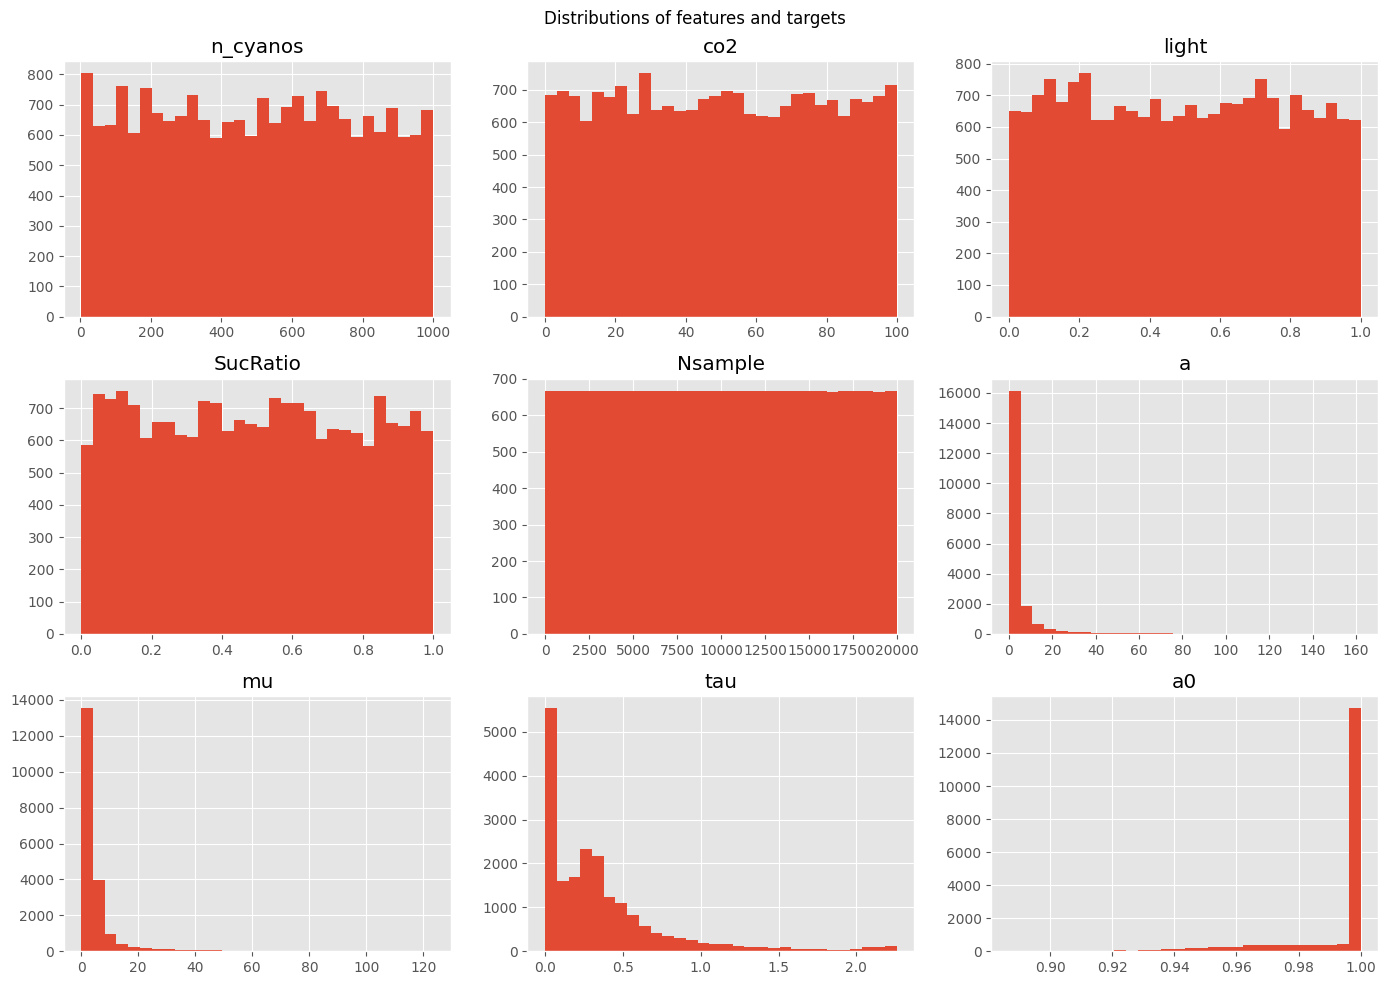

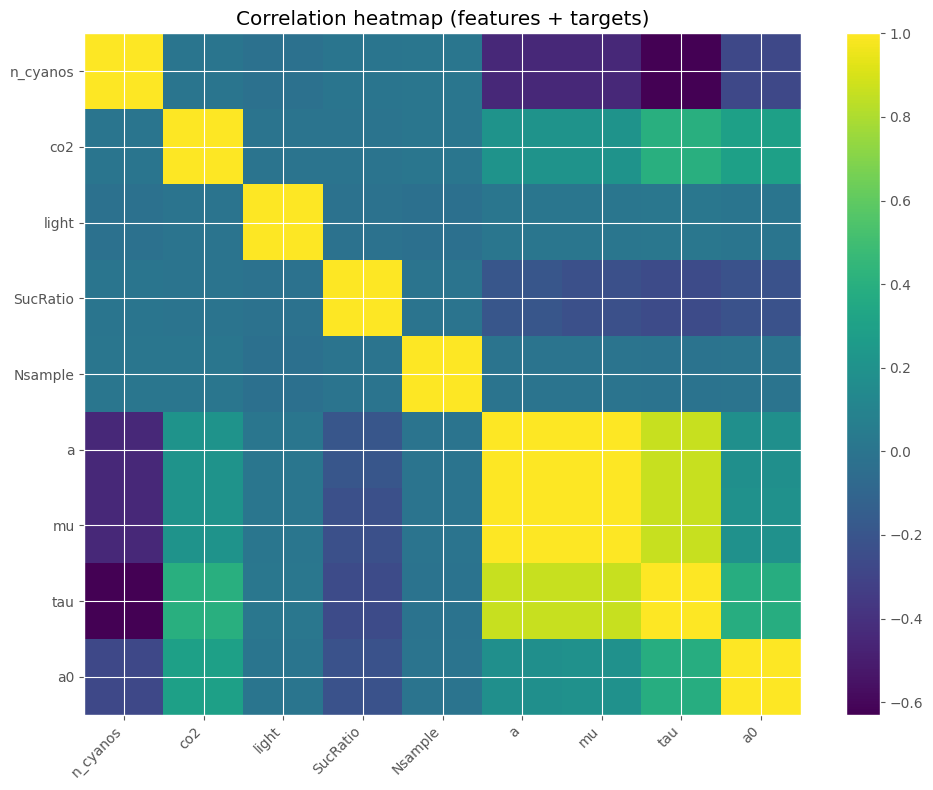

In [ ]:
#1.1)EDA PLots
#Histograms for features and targets
plt.style.use("ggplot")
cols_for_hist = ["n_cyanos", "co2", "light", "SucRatio", "Nsample", "a", "mu", "tau", "a0"]
df[cols_for_hist].hist(bins=30, figsize=(14, 10))
plt.suptitle("Distributions of features and targets")
plt.tight_layout()
plt.show()
#Correlation heatmap
corr = df[cols_for_hist].corr(numeric_only=True)
plt.figure(figsize=(10, 8))
plt.imshow(corr, aspect="auto")
plt.colorbar()
plt.xticks(range(len(cols_for_hist)), cols_for_hist, rotation=45, ha="right")
plt.yticks(range(len(cols_for_hist)), cols_for_hist)
plt.title("Correlation heatmap (features + targets)")
plt.tight_layout()
plt.show()

**Defining Features and Targets**

feature_cols = ["n_cyanos", "co2", "light", "SucRatio", "Nsample"]

targets = ["a", "mu", "tau", "a0"]

Only the five experimental condition variables are used as inputs. Other target variables are not included as features, preventing data leakage and ensuring a fair regression setup, as required by the assignment.

In [ ]:
#2) Defining features and targets
feature_cols = ["n_cyanos", "co2", "light", "SucRatio", "Nsample"]
X_all = df[feature_cols].copy()

#All numerics in dataset
numeric_features = feature_cols

**Train / Validation / Test Split**

The dataset is split into three parts. 60% training data, 20% validation data and 20% test data. The splitting of dataset allows training and hyperparameter tuning on the training set, model selection based on validation performance and unbiased evaluation on the test set.

In [ ]:
#3) Train/Validation/Test split
X_train, X_temp, y_train_df, y_temp_df = train_test_split(X_all, df[targets], test_size=0.40, random_state=42)
X_val, X_test, y_val_df, y_test_df = train_test_split(X_temp, y_temp_df, test_size=0.50, random_state=42)

print("Split sizes:")
print("Train:", X_train.shape, y_train_df.shape)
print("Val:  ", X_val.shape, y_val_df.shape)
print("Test: ", X_test.shape, y_test_df.shape)

Split sizes:
Train: (11995, 5) (11995, 4)
Val:   (3998, 5) (3998, 4)
Test:  (3999, 5) (3999, 4)


**Preprocessing Pipelines**

Two preprocessing pipelines are defined:
1. Scaled preprocessing: Used for linear regression and KNN. Scaling is required because these models depend on feature magnitudes or distances.
2. Unscaled preprocessing: Used for decision trees and random forests. Tree-based models are invariant to feature scaling and therefore do not require it.
Using Pipeline and ColumnTransformer ensures that preprocessing is learned only from the training data to avoid data leakage.


In [ ]:
#4) Preprocessing
numeric_preprocess_scaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_preprocess_unscaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocess_scaled = ColumnTransformer(
    transformers=[("num", numeric_preprocess_scaled, numeric_features)],
    remainder="drop"
)

preprocess_unscaled = ColumnTransformer(
    transformers=[("num", numeric_preprocess_unscaled, numeric_features)],
    remainder="drop"
)

**Model Pipelines and Hyperparameter Grids**

Four regression pipelines are defined:

**1. Linear Regression:** Linear regression serves as a baseline model with fit_intercept and positive used as hyperparameters.

**2. K-Nearest Neighbours:** K-Nearest neighbours is a distance-based, non-parametric regression method. With the hyperparameters being, number of neighbours, distance metric, and weighting scheme.[5]

**3. Decision Tree Regressor:** Decision tree regressor is used to capture non-linear relationships using rule-based splits. The hyperparameters here, control tree depth and minimum sample sizes to reduce overfitting.

**4. Random Forest Regressor:** Random forest regressor is an ensemble method that averages many decision trees. Hyperparameters include number of trees, depth, leaf size, and feature subsampling. This provides strong performance and robustness to noise.
The random forest space was delibeately restricted to limit computational cost while focusing on the most influential parameters.

Each pipeline is paired with a hyperparameter grid for systematic tuning using cross-validation.

In [ ]:
#5) FOUR pipelines
pipelines_and_grids = {
    "LinearRegression": (
        Pipeline(steps=[
            ("preprocess", preprocess_scaled),
            ("model", LinearRegression())
        ]),
        {
            # LinearRegression tuning
            "model__fit_intercept": [True, False],
            "model__positive": [False, True]
        }
    ),

    "KNN": (
        Pipeline(steps=[
            ("preprocess", preprocess_scaled),
            ("model", KNeighborsRegressor())
        ]),
        {
            "model__n_neighbors": [3, 5, 7, 11, 21],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    ),

    "DecisionTree": (
        Pipeline(steps=[
            ("preprocess", preprocess_unscaled),
            ("model", DecisionTreeRegressor(random_state=42))
        ]),
        {
            "model__max_depth": [None, 3, 5, 10, 20],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 5]
        }
    ),

    "RandomForest": (
        Pipeline(steps=[
            ("preprocess", preprocess_unscaled),
            ("model", RandomForestRegressor(random_state=42, n_jobs=1))
        ]),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_leaf": [1, 2, 5],
            "model__max_features": ["sqrt"]
        }
    )
}

**Metrics and Training Function**

Three regression metrics are used, RMSE(to strongly penalises large errors), MAE(to provide an interpretable average error) and R²(to measure the proportion of variance).

For every target:
1. Each pipeline is tuned using GridSearchCV on the training set.
2. The best model (lowest cross-validated RMSE) is selected.
3. Performance is evaluated on:
    * the validation set (model comparison),
    * the test set (final performance).
4. Performance is evaluated on, the validation set (model comparison) and the test set (final performance).

After obtaining the values, a structured table stores the results.

In [ ]:
#6) Metrics
def regression_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    return {"RMSE": rmse, "MAE": mae, "R2": r2}

def fit_and_evaluate_for_target(target_name, cv=5):
    y_train = y_train_df[target_name].values
    y_val   = y_val_df[target_name].values
    y_test  = y_test_df[target_name].values

    rows = []

    for pipe_name, (pipe, grid) in pipelines_and_grids.items():
        print(f"Target: {target_name} | Pipeline: {pipe_name}")

        #Hyperparameter tuning on TRAIN only
        gs = GridSearchCV(
            estimator=pipe,
            param_grid=grid,
            scoring="neg_root_mean_squared_error",
            cv=cv,
            n_jobs=-1
        )
        gs.fit(X_train, y_train)

        best_model = gs.best_estimator_
        best_params = gs.best_params_
        print("Best parameters:", best_params)
        print("Best CV RMSE:", -gs.best_score_)

        #Validation evaluation
        val_pred = best_model.predict(X_val)
        val_scores = regression_metrics(y_val, val_pred)

        #Test evaluation
        test_pred = best_model.predict(X_test)
        test_scores = regression_metrics(y_test, test_pred)

        rows.append({
            "target": target_name,
            "pipeline": pipe_name,
            "best_parameters": best_params,
            "cv_RMSE": -gs.best_score_,
            "val_RMSE": val_scores["RMSE"],
            "val_MAE": val_scores["MAE"],
            "val_R2": val_scores["R2"],
            "test_RMSE": test_scores["RMSE"],
            "test_MAE": test_scores["MAE"],
            "test_R2": test_scores["R2"],
        })

    return pd.DataFrame(rows).sort_values(by=["target", "val_RMSE"])

**Running Pipelines for All Targets**

The training function is executed separately for a, mu, tau and a0. This results in four pipelines per target, giving 16 tuned models in total. Subsequently, the best pipeline for each target is identified based on validation RMSE.

In [ ]:
#7) FOUR pipelines for EACH target (a, mu, tau, a0)
all_results = []
for t in targets:
    res_t = fit_and_evaluate_for_target(t, cv=5)
    all_results.append(res_t)

results_df = pd.concat(all_results, ignore_index=True)

Target: a | Pipeline: LinearRegression
Best parameters: {'model__fit_intercept': True, 'model__positive': False}
Best CV RMSE: 11.350018884434581
Target: a | Pipeline: KNN
Best parameters: {'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'distance'}
Best CV RMSE: 7.4198514705509595
Target: a | Pipeline: DecisionTree
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
Best CV RMSE: 2.921583109460053
Target: a | Pipeline: RandomForest
Best parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best CV RMSE: 2.328605260444624
Target: mu | Pipeline: LinearRegression
Best parameters: {'model__fit_intercept': True, 'model__positive': False}
Best CV RMSE: 8.262355215740042
Target: mu | Pipeline: KNN
Best parameters: {'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'distance'}
Best CV RMSE: 5.358332046352361
Target: mu | Pipeline: DecisionTree
Best p

**Results Tables and Visualisations**

Pivot tables are used to summarise validation and test RMSE per pipeline and target that allow easy comparison across models. Bar plots show validation RMSE for each pipeline per target and scatter plots have been used to compare actual vs predicted values on the test set for the best pipeline of each target. These visualisations help interpret model efficiency and identify systematic prediction errors.

BEST PIPELINE PER TARGET (by Validation RMSE)


,target,pipeline,cv_RMSE,val_RMSE,val_MAE,val_R2,test_RMSE,test_MAE,test_R2,best_parameters
0,a,RandomForest,2.328605,2.292448,0.549021,0.970582,2.708827,0.570554,0.961425,"{'model__max_depth': None, 'model__max_feature..."
12,a0,RandomForest,0.009751,0.009255,0.004259,0.689947,0.009748,0.004537,0.688710,"{'model__max_depth': 20, 'model__max_features'..."
4,mu,RandomForest,1.797743,1.727771,0.485686,0.968750,1.992994,0.492784,0.961184,"{'model__max_depth': 20, 'model__max_features'..."
8,tau,RandomForest,0.041454,0.038337,0.021658,0.991675,0.048225,0.023313,0.986901,"{'model__max_depth': 20, 'model__max_features'..."



Full results (sorted by target, then val_RMSE):


,target,pipeline,best_parameters,cv_RMSE,val_RMSE,val_MAE,val_R2,test_RMSE,test_MAE,test_R2
0,a,RandomForest,"{'model__max_depth': None, 'model__max_feature...",2.328605,2.292448,0.549021,0.970582,2.708827,0.570554,0.961425
1,a,DecisionTree,"{'model__max_depth': None, 'model__min_samples...",2.921583,3.602051,0.833514,0.927371,3.301722,0.788394,0.942691
2,a,KNN,"{'model__n_neighbors': 7, 'model__p': 1, 'mode...",7.419851,7.232583,1.893468,0.707183,7.577625,1.899942,0.698141
3,a,LinearRegression,"{'model__fit_intercept': True, 'model__positiv...",11.350019,11.302496,5.826002,0.284915,11.722998,5.950394,0.277537
4,mu,RandomForest,"{'model__max_depth': 20, 'model__max_features'...",1.797743,1.727771,0.485686,0.968750,1.992994,0.492784,0.961184
5,mu,DecisionTree,"{'model__max_depth': None, 'model__min_samples...",2.170508,2.588938,0.709030,0.929835,2.451862,0.683232,0.941252
6,mu,KNN,"{'model__n_neighbors': 7, 'model__p': 1, 'mode...",5.358332,5.157539,1.459150,0.721539,5.455104,1.472053,0.709192
7,mu,LinearRegression,"{'model__fit_intercept': True, 'model__positiv...",8.262355,8.169005,4.196968,0.301417,8.523751,4.307497,0.289994
8,tau,RandomForest,"{'model__max_depth': 20, 'model__max_features'...",0.041454,0.038337,0.021658,0.991675,0.048225,0.023313,0.986901
9,tau,DecisionTree,"{'model__max_depth': None, 'model__min_samples...",0.059453,0.052207,0.031212,0.984561,0.055067,0.031333,0.982920


Validation RMSE table (pipeline x target):


target,a,a0,mu,tau
pipeline,,,,
DecisionTree,3.602051,0.010821,2.588938,0.052207
KNN,7.232583,0.010710,5.157539,0.139237
LinearRegression,11.302496,0.014696,8.169005,0.256394
RandomForest,2.292448,0.009255,1.727771,0.038337


Test RMSE table (pipeline x target):


target,a,a0,mu,tau
pipeline,,,,
DecisionTree,3.301722,0.011312,2.451862,0.055067
KNN,7.577625,0.011255,5.455104,0.140578
LinearRegression,11.722998,0.015548,8.523751,0.259018
RandomForest,2.708827,0.009748,1.992994,0.048225


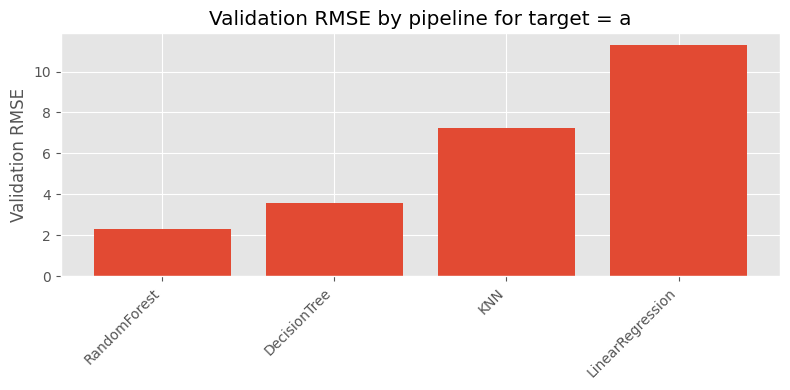

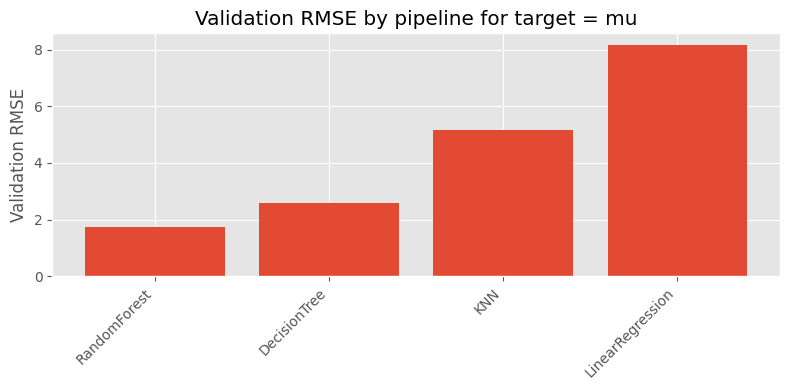

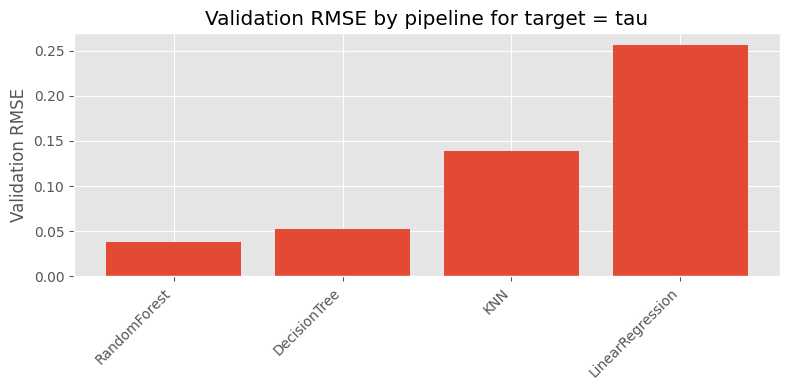

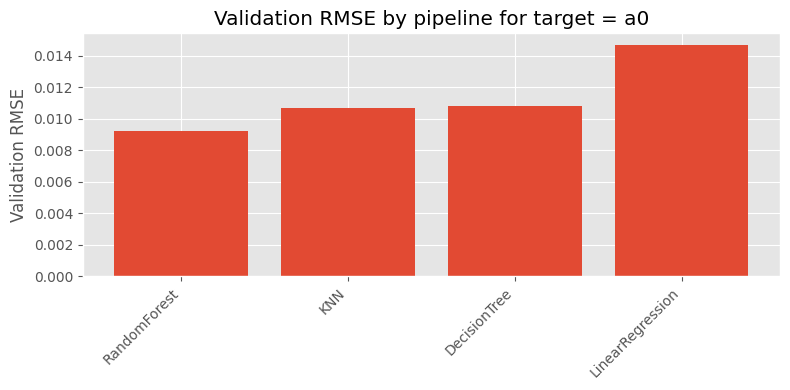

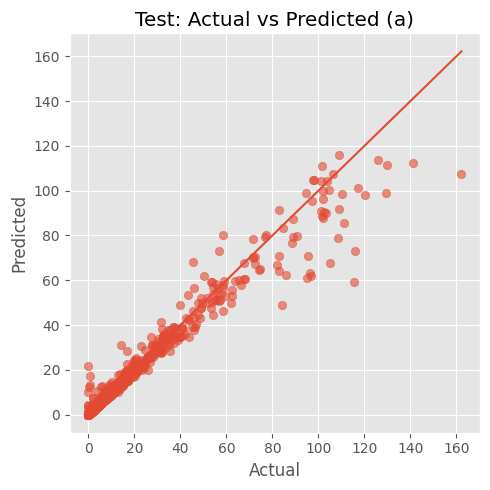

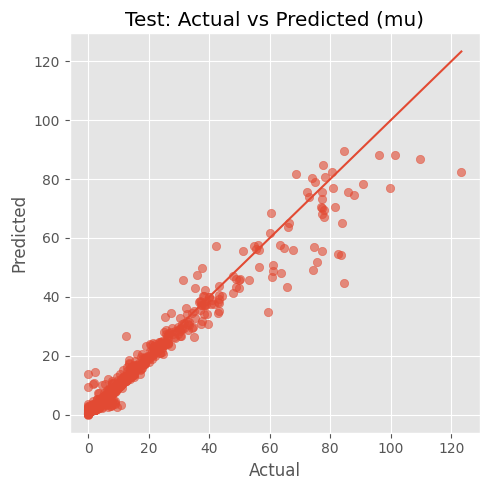

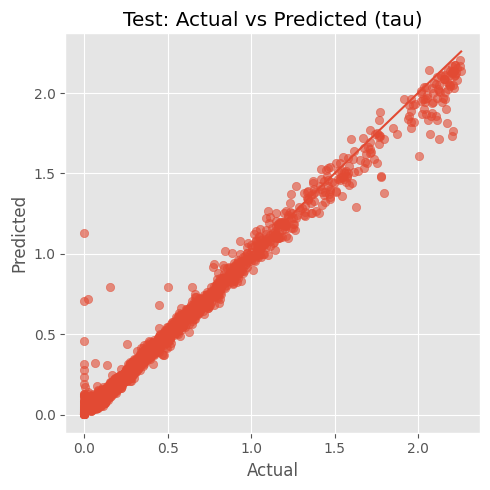

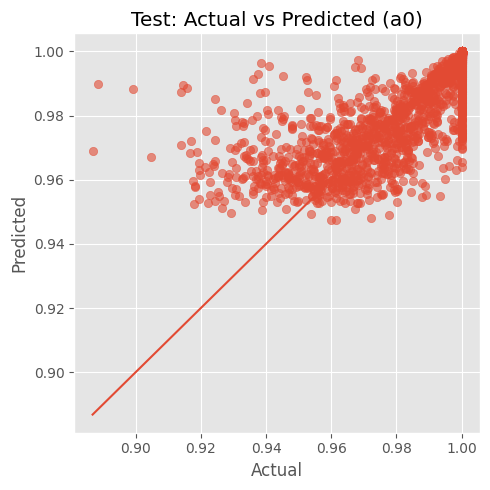

Best pipeline: RandomForest


In [ ]:
#8) Summary
#Best pipeline per target by validation RMSE
best_by_target = results_df.sort_values(["target", "val_RMSE"]).groupby("target", as_index=False).head(1)

print("BEST PIPELINE PER TARGET (by Validation RMSE)")
display(best_by_target[[
    "target","pipeline","cv_RMSE","val_RMSE","val_MAE","val_R2","test_RMSE","test_MAE","test_R2","best_parameters"
]])

print("\nFull results (sorted by target, then val_RMSE):")
display(results_df)

#Pivot tables (summary tables)
val_rmse_table = results_df.pivot_table(index="pipeline", columns="target", values="val_RMSE")
test_rmse_table = results_df.pivot_table(index="pipeline", columns="target", values="test_RMSE")
print("Validation RMSE table (pipeline x target):")
display(val_rmse_table)
print("Test RMSE table (pipeline x target):")
display(test_rmse_table)

#Bar plots: Validation RMSE per pipeline for each target
for t in targets:
    df_t = results_df[results_df["target"] == t].sort_values("val_RMSE")
    plt.figure(figsize=(8, 4))
    plt.bar(df_t["pipeline"], df_t["val_RMSE"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Validation RMSE")
    plt.title(f"Validation RMSE by pipeline for target = {t}")
    plt.tight_layout()
    plt.show()

#Scatter plots: Best model (by val RMSE) predicted vs actual on TEST for each target
for t in targets:
    best_pipeline_name = best_by_target[best_by_target["target"] == t]["pipeline"].iloc[0]
    pipe, grid = pipelines_and_grids[best_pipeline_name]

    gs_best = GridSearchCV(
        estimator=pipe,
        param_grid=grid,
        scoring="neg_root_mean_squared_error",
        cv=5,
        n_jobs=-1
    )
    gs_best.fit(X_train, y_train_df[t].values)
    best_model = gs_best.best_estimator_

    y_true = y_test_df[t].values
    y_pred = best_model.predict(X_test)

    plt.figure(figsize=(5, 5))
    plt.scatter(y_true, y_pred, alpha=0.6)
    mn = min(y_true.min(), y_pred.min())
    mx = max(y_true.max(), y_pred.max())
    plt.plot([mn, mx], [mn, mx])
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"Test: Actual vs Predicted ({t})")
    plt.tight_layout()
    plt.show()

print(f"Best pipeline: {best_pipeline_name}")

**Conclusion**

This code implements a complete regression workflow that follows the required experimental setup and prevents data leakage. The preprocessing is performed appropriately for each model. This model trains and executes four distinct pipelines per target and uses appropriate regression metrics that evaluates performance. The results are presents using tables and plots.

**References**

[1] CSC8635 Machine Learning - Synthetic Minority Oversampling Technique()SMOTE - Lecture: Data Preprocessing

[2] CSC8635 Machine Learning - Decision Trees - Lecture: Decision Trees, Random Forest, Nearest Neighbour Classifiers

[3] CSC8635 Machine Learning - RANDOM FOREST - Lecture: Decision Trees, Random Forest, Nearest Neighbour Classifiers

[4] CSC8635 Machine Learning - LOGISTIC REGRESSION - Lecture: Decision Trees, Random Forest, Nearest Neighbour Classifiers

[5] CSC8635 Machine Learning - k-NN - Lecture: Decision Trees, Random Forest, Nearest Neighbour Classifiers